# Challenge Intermedio: Modelado con Spark ML
## Predicción de Calidad de Vino usando PySpark.Pandas y Spark MLlib

**Autor:** Carlos Pulido Rosas

**Universidad:** Universidad de Guadalajara - Campus CUCEA

**Maestria:** Ciencia de los Datos

**Materia:** Procesamiento de Grandes Bases de Datos

**Dataset:** Wine Quality Dataset

**Fuente:** [UCI Machine Learning Repository - Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality)

---

## Descripción del Dataset

El Wine Quality Dataset contiene información sobre vinos tintos y blancos de la variedad portuguesa "Vinho Verde". 

**Características:**
- **Variables de entrada (11):** Basadas en pruebas fisicoquímicas
  - Fixed acidity, Volatile acidity, Citric acid, Residual sugar, Chlorides
  - Free sulfur dioxide, Total sulfur dioxide, Density, pH, Sulphates, Alcohol
- **Variable objetivo:** Quality (puntuación de 0-10 basada en evaluación sensorial)
- **Observaciones:** ~6,500 muestras (4,898 vinos blancos + 1,599 vinos tintos)

## Objetivo

1. Descargar y cargar datos usando **ucimlrepo** y **PySpark.Pandas (Koalas)**
2. Realizar limpieza y preparación de datos
3. Entrenar un modelo de **clasificación** usando **Spark MLlib**
4. Evaluar el modelo y generar métricas de rendimiento
5. Documentar resultados y conclusiones

## 1. Configuración e Importación de Librerías

In [1]:
# Importar librerías necesarias
import pyspark.pandas as ps  # API de Koalas para PySpark
from pyspark import __version__ as pyspark_version
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *

# Spark MLlib para Machine Learning
from pyspark.ml.feature import VectorAssembler, StandardScaler, StringIndexer
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, DecisionTreeClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml import Pipeline

# Librerías para visualización
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Configurar estilo
sns.set_style('whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (12, 6)

print("✓ Librerías importadas exitosamente")
print(f"✓ PySpark versión: {pyspark_version}")

c:\Users\carlo\anaconda3\envs\ai_automation_thesis\lib\site-packages\pyspark\pandas\__init__.py:50: UserWarning: 'PYARROW_IGNORE_TIMEZONE' environment variable was not set. It is required to set this environment variable to '1' in both driver and executor sides if you use pyarrow>=2.0.0. pandas-on-Spark will set it for you but it does not work if there is a Spark context already launched.
  warnings.warn(


✓ Librerías importadas exitosamente
✓ PySpark versión: 3.5.0


In [2]:
# Configuración de Spark para Windows
from pyspark.sql import SparkSession
import os

# Detener cualquier sesión existente
try:
    spark = SparkSession.getActiveSession()
    if spark:
        spark.stop()
except:
    pass

# Crear sesión de Spark optimizada
spark = SparkSession.builder \
    .appName("Wine_Quality_ML") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .config("spark.driver.host", "127.0.0.1") \
    .config("spark.driver.bindAddress", "127.0.0.1") \
    .config("spark.sql.shuffle.partitions", "4") \
    .master("local[*]") \
    .getOrCreate()

# Configurar PySpark.Pandas
ps.set_option('compute.default_index_type', 'distributed')
ps.set_option('compute.ops_on_diff_frames', True)

print("✓ Sesión de Spark configurada")
print(f"Versión de Spark: {spark.version}")
print(f"Master: {spark.sparkContext.master}")

✓ Sesión de Spark configurada
Versión de Spark: 3.5.6
Master: local[*]


## 2. Descarga y Carga de Datos

In [4]:
# Descargar dataset desde UCI usando ucimlrepo
print("Paso 1: Descargando Wine Quality Dataset desde UCI...")
print("-" * 60)

from ucimlrepo import fetch_ucirepo

# Fetch dataset (ID 186 = Wine Quality)
wine_quality = fetch_ucirepo(id=186)

print("✓ Dataset descargado exitosamente")
print(f"\nMetadata:")
print(wine_quality.metadata)

Paso 1: Descargando Wine Quality Dataset desde UCI...
------------------------------------------------------------
✓ Dataset descargado exitosamente

Metadata:
{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'c

In [5]:
# Extraer features y target
X = wine_quality.data.features  # Features (pandas DataFrame)
y = wine_quality.data.targets    # Target (pandas DataFrame)

print("\nInformación de Features:")
print(f"  Dimensiones: {X.shape}")
print(f"  Columnas: {list(X.columns)}")

print("\nInformación de Target:")
print(f"  Dimensiones: {y.shape}")
print(f"  Columnas: {list(y.columns)}")


Información de Features:
  Dimensiones: (6497, 11)
  Columnas: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Información de Target:
  Dimensiones: (6497, 1)
  Columnas: ['quality']


In [6]:
# Combinar features y target en un solo DataFrame
df_pandas = pd.concat([X, y], axis=1)

print("\nDataset combinado (Pandas):")
print(f"  Dimensiones: {df_pandas.shape}")
print(f"  Columnas: {list(df_pandas.columns)}")

# Mostrar primeras filas
print("\nPrimeras 5 filas:")
df_pandas.head()


Dataset combinado (Pandas):
  Dimensiones: (6497, 12)
  Columnas: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Primeras 5 filas:


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [7]:
# Convertir a PySpark.Pandas (Koalas)
print("Paso 2: Convirtiendo a PySpark.Pandas (Koalas)...")
print("-" * 60)

df_koalas = ps.from_pandas(df_pandas)

print(f"✓ Dataset convertido a PySpark.Pandas")
print(f"  Tipo: {type(df_koalas)}")
print(f"  Dimensiones: {df_koalas.shape}")

Paso 2: Convirtiendo a PySpark.Pandas (Koalas)...
------------------------------------------------------------
✓ Dataset convertido a PySpark.Pandas
  Tipo: <class 'pyspark.pandas.frame.DataFrame'>
  Dimensiones: (6497, 12)


## 3. Análisis Exploratorio de Datos

In [8]:
# Información general del dataset
print("Información del Dataset:")
print(f"\nNúmero de filas: {len(df_koalas):,}")
print(f"Número de columnas: {len(df_koalas.columns)}")
print(f"\nColumnas:")
for i, col in enumerate(df_koalas.columns, 1):
    print(f"  {i:2d}. {col}")

Información del Dataset:

Número de filas: 6,497
Número de columnas: 12

Columnas:
   1. fixed_acidity
   2. volatile_acidity
   3. citric_acid
   4. residual_sugar
   5. chlorides
   6. free_sulfur_dioxide
   7. total_sulfur_dioxide
   8. density
   9. pH
  10. sulphates
  11. alcohol
  12. quality


In [9]:
# Verificar valores nulos
print("Valores nulos por columna:")
nulls = df_koalas.isna().sum().to_pandas()
print(nulls)

print(f"\nTotal de valores nulos: {nulls.sum()}")

Valores nulos por columna:
fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total de valores nulos: 0


In [10]:
# Distribución de la variable objetivo (quality)
print("Distribución de Calidad del Vino:")
quality_dist = df_koalas['quality'].value_counts().sort_index().to_pandas()
print(quality_dist)

print(f"\nRango de calidad: {df_koalas['quality'].min()} - {df_koalas['quality'].max()}")

Distribución de Calidad del Vino:
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: quality, dtype: int64

Rango de calidad: 3 - 9


In [11]:
# Estadísticas descriptivas de features numéricas
print("Estadísticas descriptivas (primeras 6 columnas):")

# Seleccionar features numéricas
numeric_cols = ['fixed_acidity', 'volatile_acidity', 'citric_acid', 
                'residual_sugar', 'chlorides', 'free_sulfur_dioxide']

stats_df = df_koalas[numeric_cols].describe().to_pandas()
print(stats_df)

Estadísticas descriptivas (primeras 6 columnas):
       fixed_acidity  volatile_acidity  citric_acid  residual_sugar  \
count    6497.000000       6497.000000  6497.000000     6497.000000   
mean        7.215307          0.339666     0.318633        5.443235   
std         1.296434          0.164636     0.145318        4.757804   
min         3.800000          0.080000     0.000000        0.600000   
25%         6.400000          0.230000     0.250000        1.800000   
50%         7.000000          0.290000     0.310000        3.000000   
75%         7.700000          0.400000     0.390000        8.100000   
max        15.900000          1.580000     1.660000       65.800000   

         chlorides  free_sulfur_dioxide  
count  6497.000000          6497.000000  
mean      0.056034            30.525319  
std       0.035034            17.749400  
min       0.009000             1.000000  
25%       0.038000            17.000000  
50%       0.047000            29.000000  
75%       0.06500

## 4. Visualizaciones Exploratorias

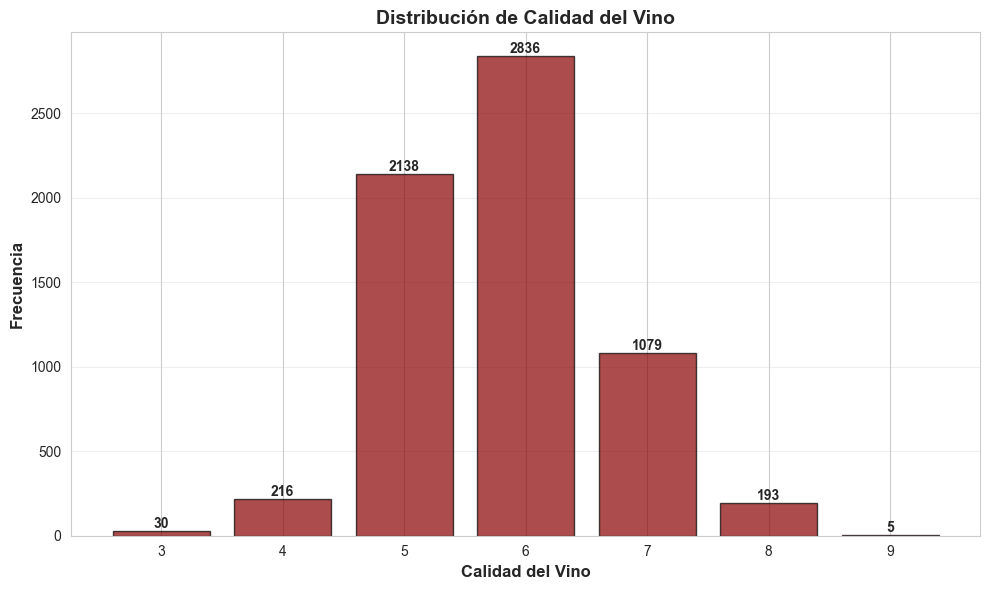

✓ Visualización 1 guardada: viz_1_distribucion_calidad.png


In [12]:
# Convertir a pandas para visualizaciones
df_vis = df_koalas.to_pandas()

# Distribución de calidad del vino
plt.figure(figsize=(10, 6))
quality_counts = df_vis['quality'].value_counts().sort_index()
bars = plt.bar(quality_counts.index, quality_counts.values, 
               color='darkred', edgecolor='black', alpha=0.7)

# Agregar valores en las barras
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.xlabel('Calidad del Vino', fontsize=12, fontweight='bold')
plt.ylabel('Frecuencia', fontsize=12, fontweight='bold')
plt.title('Distribución de Calidad del Vino', fontsize=14, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('viz_1_distribucion_calidad.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 1 guardada: viz_1_distribucion_calidad.png")

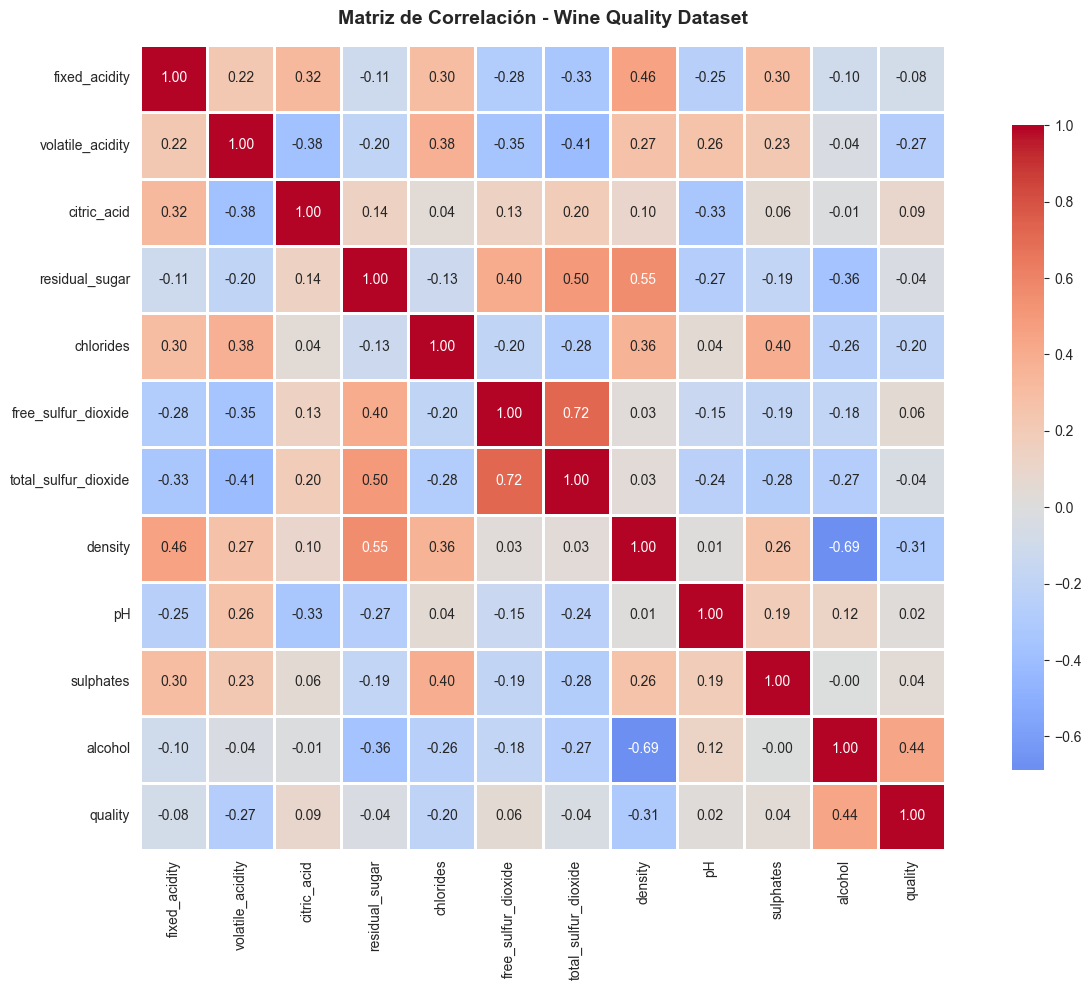

✓ Visualización 2 guardada: viz_2_correlacion.png


In [13]:
# Matriz de correlación
plt.figure(figsize=(14, 10))

# Calcular correlación
correlation = df_vis.corr()

# Crear heatmap
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})

plt.title('Matriz de Correlación - Wine Quality Dataset', 
          fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('viz_2_correlacion.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 2 guardada: viz_2_correlacion.png")

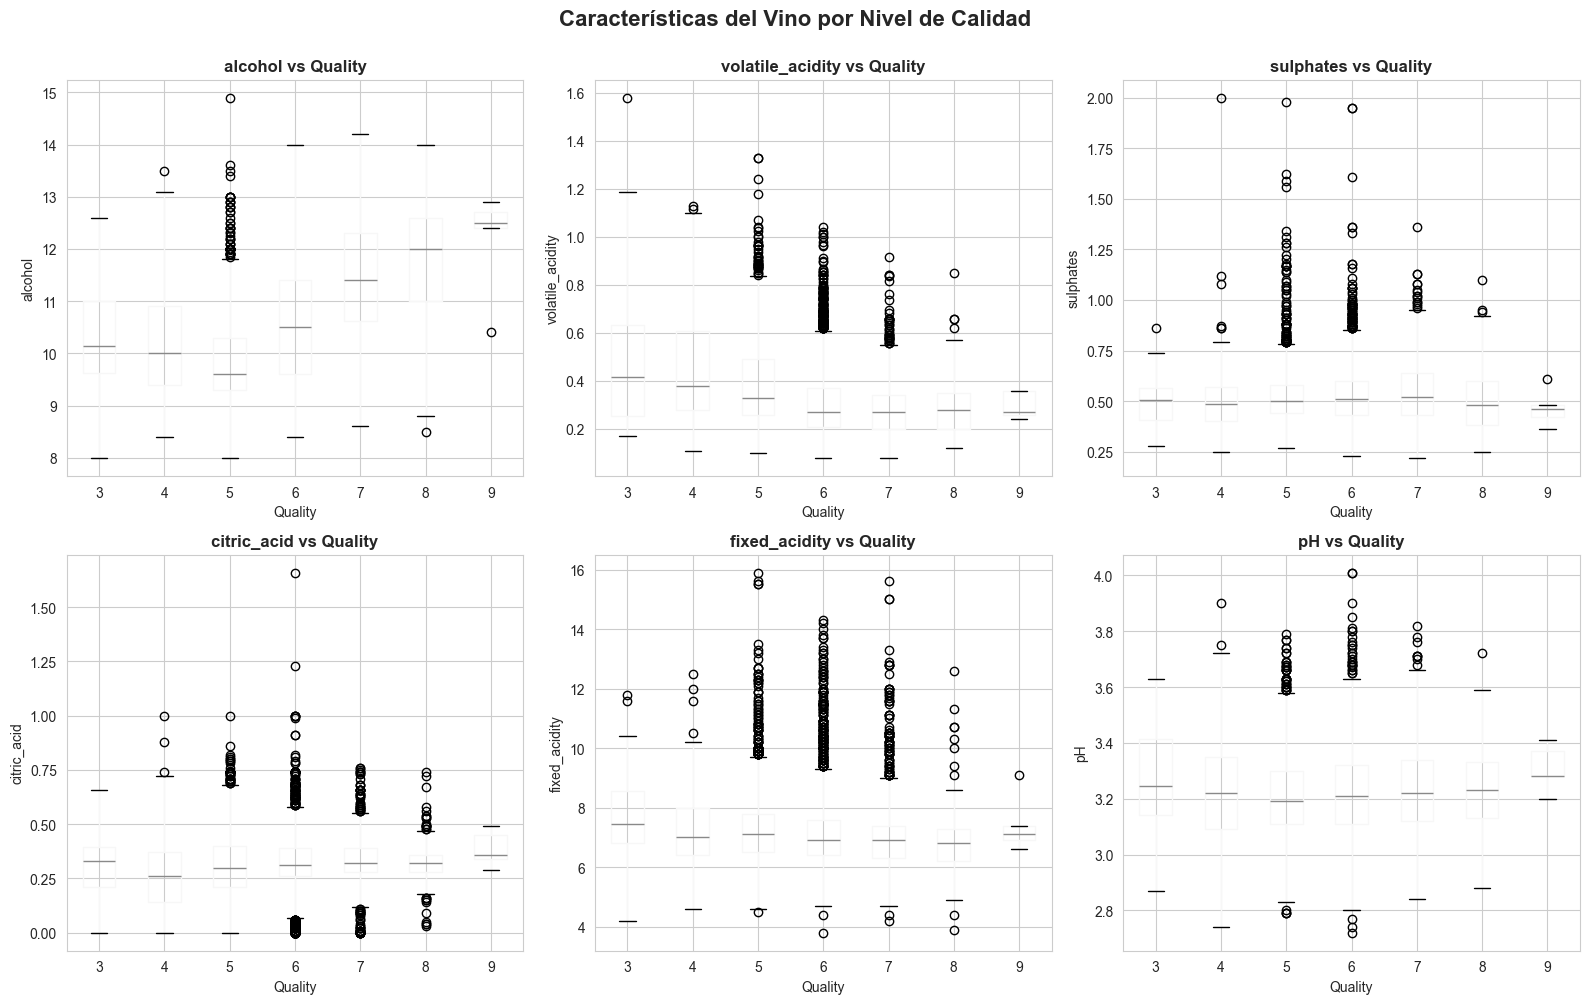

✓ Visualización 3 guardada: viz_3_features_quality.png


In [14]:
# Boxplots de features principales vs quality
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
features_plot = ['alcohol', 'volatile_acidity', 'sulphates', 
                 'citric_acid', 'fixed_acidity', 'pH']

for idx, feature in enumerate(features_plot):
    row = idx // 3
    col = idx % 3
    
    df_vis.boxplot(column=feature, by='quality', ax=axes[row, col])
    axes[row, col].set_title(f'{feature} vs Quality', fontweight='bold')
    axes[row, col].set_xlabel('Quality')
    axes[row, col].set_ylabel(feature)

plt.suptitle('Características del Vino por Nivel de Calidad', 
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('viz_3_features_quality.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 3 guardada: viz_3_features_quality.png")

## 5. Preparación de Datos para Machine Learning

In [15]:
# Convertir a Spark DataFrame (necesario para Spark MLlib)
print("Convirtiendo a Spark DataFrame para MLlib...")

df_spark = df_koalas.to_spark()

print(f"✓ Conversión completada")
print(f"  Tipo: {type(df_spark)}")
print(f"  Número de filas: {df_spark.count():,}")

# Mostrar esquema
print("\nEsquema del Spark DataFrame:")
df_spark.printSchema()

Convirtiendo a Spark DataFrame para MLlib...
✓ Conversión completada
  Tipo: <class 'pyspark.sql.dataframe.DataFrame'>
  Número de filas: 6,497

Esquema del Spark DataFrame:
root
 |-- fixed_acidity: double (nullable = false)
 |-- volatile_acidity: double (nullable = false)
 |-- citric_acid: double (nullable = false)
 |-- residual_sugar: double (nullable = false)
 |-- chlorides: double (nullable = false)
 |-- free_sulfur_dioxide: double (nullable = false)
 |-- total_sulfur_dioxide: double (nullable = false)
 |-- density: double (nullable = false)
 |-- pH: double (nullable = false)
 |-- sulphates: double (nullable = false)
 |-- alcohol: double (nullable = false)
 |-- quality: long (nullable = false)



In [16]:
# Limpiar nombres de columnas (eliminar espacios)
for col_name in df_spark.columns:
    new_col_name = col_name.replace(' ', '_')
    df_spark = df_spark.withColumnRenamed(col_name, new_col_name)

print("✓ Nombres de columnas limpiados")
print(f"Columnas: {df_spark.columns}")

✓ Nombres de columnas limpiados
Columnas: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [19]:
# Crear clasificación binaria/multiclase simplificada
# Agrupar calidades en 3 categorías: Baja (3-5), Media (6), Alta (7-9)

from pyspark.sql.functions import when, col

df_spark = df_spark.withColumn(
    'quality_category',
    when(col('quality') <= 5, 'Baja')
    .when(col('quality') == 6, 'Media')
    .otherwise('Alta')
)

print("✓ Columna 'quality_category' creada")
print("\nDistribución de categorías:")
df_spark.groupBy('quality_category').count().show()

✓ Columna 'quality_category' creada

Distribución de categorías:
+----------------+-----+
|quality_category|count|
+----------------+-----+
|           Media| 2836|
|            Baja| 2384|
|            Alta| 1277|
+----------------+-----+



In [20]:
# Preparar features para el modelo
feature_columns = [
    'fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar',
    'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density',
    'pH', 'sulphates', 'alcohol'
]

print(f"Features a utilizar ({len(feature_columns)}):")
for i, feat in enumerate(feature_columns, 1):
    print(f"  {i:2d}. {feat}")

Features a utilizar (11):
   1. fixed_acidity
   2. volatile_acidity
   3. citric_acid
   4. residual_sugar
   5. chlorides
   6. free_sulfur_dioxide
   7. total_sulfur_dioxide
   8. density
   9. pH
  10. sulphates
  11. alcohol


In [21]:
# Eliminar filas con valores nulos (si existen)
df_spark_clean = df_spark.dropna()

print(f"Filas antes de limpieza: {df_spark.count():,}")
print(f"Filas después de limpieza: {df_spark_clean.count():,}")
print(f"Filas eliminadas: {df_spark.count() - df_spark_clean.count():,}")

Filas antes de limpieza: 6,497
Filas después de limpieza: 6,497
Filas eliminadas: 0


## 6. Construcción del Pipeline de Machine Learning

In [22]:
# Dividir en train y test
print("Dividiendo dataset en train (80%) y test (20%)...")

train_data, test_data = df_spark_clean.randomSplit([0.8, 0.2], seed=42)

print(f"\n✓ División completada")
print(f"  Train: {train_data.count():,} filas ({train_data.count()/df_spark_clean.count()*100:.1f}%)")
print(f"  Test:  {test_data.count():,} filas ({test_data.count()/df_spark_clean.count()*100:.1f}%)")

Dividiendo dataset en train (80%) y test (20%)...

✓ División completada
  Train: 5,219 filas (80.3%)
  Test:  1,278 filas (19.7%)


In [23]:
# Crear pipeline de transformación
print("\nCreando Pipeline de Machine Learning...")
print("-" * 60)

# 1. Indexar la variable categórica (quality_category)
label_indexer = StringIndexer(inputCol='quality_category', outputCol='label')

# 2. Ensamblar features en un vector
assembler = VectorAssembler(inputCols=feature_columns, outputCol='features_raw')

# 3. Escalar features (normalización)
scaler = StandardScaler(inputCol='features_raw', outputCol='features')

print("✓ Transformadores creados:")
print("  1. StringIndexer - Convertir categorías a índices numéricos")
print("  2. VectorAssembler - Ensamblar features en vector")
print("  3. StandardScaler - Normalizar features")


Creando Pipeline de Machine Learning...
------------------------------------------------------------
✓ Transformadores creados:
  1. StringIndexer - Convertir categorías a índices numéricos
  2. VectorAssembler - Ensamblar features en vector
  3. StandardScaler - Normalizar features


## 7. Entrenamiento de Modelos

### 7.1 Modelo 1: Regresión Logística

In [24]:
# Modelo 1: Regresión Logística
print("Entrenando Modelo 1: Regresión Logística...")
print("-" * 60)

lr = LogisticRegression(featuresCol='features', labelCol='label', 
                        maxIter=100, regParam=0.01)

# Crear pipeline completo
pipeline_lr = Pipeline(stages=[label_indexer, assembler, scaler, lr])

# Entrenar modelo
print("Entrenando modelo...")
model_lr = pipeline_lr.fit(train_data)

print("✓ Modelo de Regresión Logística entrenado")

Entrenando Modelo 1: Regresión Logística...
------------------------------------------------------------
Entrenando modelo...
✓ Modelo de Regresión Logística entrenado


In [25]:
# Realizar predicciones
predictions_lr = model_lr.transform(test_data)

print("Predicciones realizadas")
print("\nPrimeras 10 predicciones:")
predictions_lr.select('quality_category', 'label', 'prediction', 'probability').show(10, truncate=False)

Predicciones realizadas

Primeras 10 predicciones:
+----------------+-----+----------+-------------------------------------------------------------+
|quality_category|label|prediction|probability                                                  |
+----------------+-----+----------+-------------------------------------------------------------+
|Baja            |1.0  |1.0       |[0.1331238648685205,0.8546413400637043,0.012234795067775327] |
|Alta            |2.0  |0.0       |[0.5468072200555797,0.1855517573766581,0.2676410225677621]   |
|Baja            |1.0  |1.0       |[0.32218170074873714,0.6523948358345666,0.025423463416696275]|
|Baja            |1.0  |1.0       |[0.05127616596621342,0.947816058683406,9.077753503805622E-4] |
|Media           |0.0  |0.0       |[0.5720251951506876,0.2704875210767829,0.1574872837725294]   |
|Baja            |1.0  |1.0       |[0.36891043050193156,0.6007854703439257,0.030304099154142883]|
|Baja            |1.0  |1.0       |[0.2902132371821203,0.6921886849

In [26]:
# Evaluar modelo de Regresión Logística
evaluator_acc = MulticlassClassificationEvaluator(labelCol='label', 
                                                   predictionCol='prediction', 
                                                   metricName='accuracy')
evaluator_f1 = MulticlassClassificationEvaluator(labelCol='label', 
                                                  predictionCol='prediction', 
                                                  metricName='f1')
evaluator_precision = MulticlassClassificationEvaluator(labelCol='label', 
                                                         predictionCol='prediction', 
                                                         metricName='weightedPrecision')
evaluator_recall = MulticlassClassificationEvaluator(labelCol='label', 
                                                      predictionCol='prediction', 
                                                      metricName='weightedRecall')

accuracy_lr = evaluator_acc.evaluate(predictions_lr)
f1_lr = evaluator_f1.evaluate(predictions_lr)
precision_lr = evaluator_precision.evaluate(predictions_lr)
recall_lr = evaluator_recall.evaluate(predictions_lr)

print("\n" + "="*60)
print("RESULTADOS - REGRESIÓN LOGÍSTICA")
print("="*60)
print(f"Accuracy:  {accuracy_lr:.4f} ({accuracy_lr*100:.2f}%)")
print(f"F1-Score:  {f1_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall:    {recall_lr:.4f}")
print("="*60)


RESULTADOS - REGRESIÓN LOGÍSTICA
Accuracy:  0.5673 (56.73%)
F1-Score:  0.5569
Precision: 0.5742
Recall:    0.5673


### 7.2 Modelo 2: Random Forest

In [27]:
# Modelo 2: Random Forest Classifier
print("\nEntrenando Modelo 2: Random Forest...")
print("-" * 60)

rf = RandomForestClassifier(featuresCol='features', labelCol='label', 
                            numTrees=100, maxDepth=10, seed=42)

# Crear pipeline
pipeline_rf = Pipeline(stages=[label_indexer, assembler, scaler, rf])

# Entrenar modelo
print("Entrenando modelo...")
model_rf = pipeline_rf.fit(train_data)

print("✓ Modelo de Random Forest entrenado")


Entrenando Modelo 2: Random Forest...
------------------------------------------------------------
Entrenando modelo...
✓ Modelo de Random Forest entrenado


In [28]:
# Realizar predicciones con Random Forest
predictions_rf = model_rf.transform(test_data)

# Evaluar modelo
accuracy_rf = evaluator_acc.evaluate(predictions_rf)
f1_rf = evaluator_f1.evaluate(predictions_rf)
precision_rf = evaluator_precision.evaluate(predictions_rf)
recall_rf = evaluator_recall.evaluate(predictions_rf)

print("\n" + "="*60)
print("RESULTADOS - RANDOM FOREST")
print("="*60)
print(f"Accuracy:  {accuracy_rf:.4f} ({accuracy_rf*100:.2f}%)")
print(f"F1-Score:  {f1_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print("="*60)


RESULTADOS - RANDOM FOREST
Accuracy:  0.6682 (66.82%)
F1-Score:  0.6670
Precision: 0.6717
Recall:    0.6682


### 7.3 Modelo 3: Decision Tree

In [29]:
# Modelo 3: Decision Tree Classifier
print("\nEntrenando Modelo 3: Decision Tree...")
print("-" * 60)

dt = DecisionTreeClassifier(featuresCol='features', labelCol='label', 
                            maxDepth=10, seed=42)

# Crear pipeline
pipeline_dt = Pipeline(stages=[label_indexer, assembler, scaler, dt])

# Entrenar modelo
print("Entrenando modelo...")
model_dt = pipeline_dt.fit(train_data)

print("✓ Modelo de Decision Tree entrenado")


Entrenando Modelo 3: Decision Tree...
------------------------------------------------------------
Entrenando modelo...
✓ Modelo de Decision Tree entrenado


In [30]:
# Realizar predicciones con Decision Tree
predictions_dt = model_dt.transform(test_data)

# Evaluar modelo
accuracy_dt = evaluator_acc.evaluate(predictions_dt)
f1_dt = evaluator_f1.evaluate(predictions_dt)
precision_dt = evaluator_precision.evaluate(predictions_dt)
recall_dt = evaluator_recall.evaluate(predictions_dt)

print("\n" + "="*60)
print("RESULTADOS - DECISION TREE")
print("="*60)
print(f"Accuracy:  {accuracy_dt:.4f} ({accuracy_dt*100:.2f}%)")
print(f"F1-Score:  {f1_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall:    {recall_dt:.4f}")
print("="*60)


RESULTADOS - DECISION TREE
Accuracy:  0.5861 (58.61%)
F1-Score:  0.5852
Precision: 0.5857
Recall:    0.5861


## 8. Comparación de Modelos

In [31]:
# Crear tabla comparativa
resultados = pd.DataFrame({
    'Modelo': ['Regresión Logística', 'Random Forest', 'Decision Tree'],
    'Accuracy': [accuracy_lr, accuracy_rf, accuracy_dt],
    'F1-Score': [f1_lr, f1_rf, f1_dt],
    'Precision': [precision_lr, precision_rf, precision_dt],
    'Recall': [recall_lr, recall_rf, recall_dt]
})

print("\n" + "="*80)
print("COMPARACIÓN DE MODELOS")
print("="*80)
print(resultados.to_string(index=False))
print("="*80)

# Identificar mejor modelo
mejor_modelo_idx = resultados['Accuracy'].idxmax()
mejor_modelo = resultados.loc[mejor_modelo_idx, 'Modelo']
mejor_accuracy = resultados.loc[mejor_modelo_idx, 'Accuracy']

print(f"\n🏆 MEJOR MODELO: {mejor_modelo}")
print(f"   Accuracy: {mejor_accuracy:.4f} ({mejor_accuracy*100:.2f}%)")


COMPARACIÓN DE MODELOS
             Modelo  Accuracy  F1-Score  Precision   Recall
Regresión Logística  0.567293  0.556945   0.574164 0.567293
      Random Forest  0.668232  0.667029   0.671706 0.668232
      Decision Tree  0.586072  0.585244   0.585673 0.586072

🏆 MEJOR MODELO: Random Forest
   Accuracy: 0.6682 (66.82%)


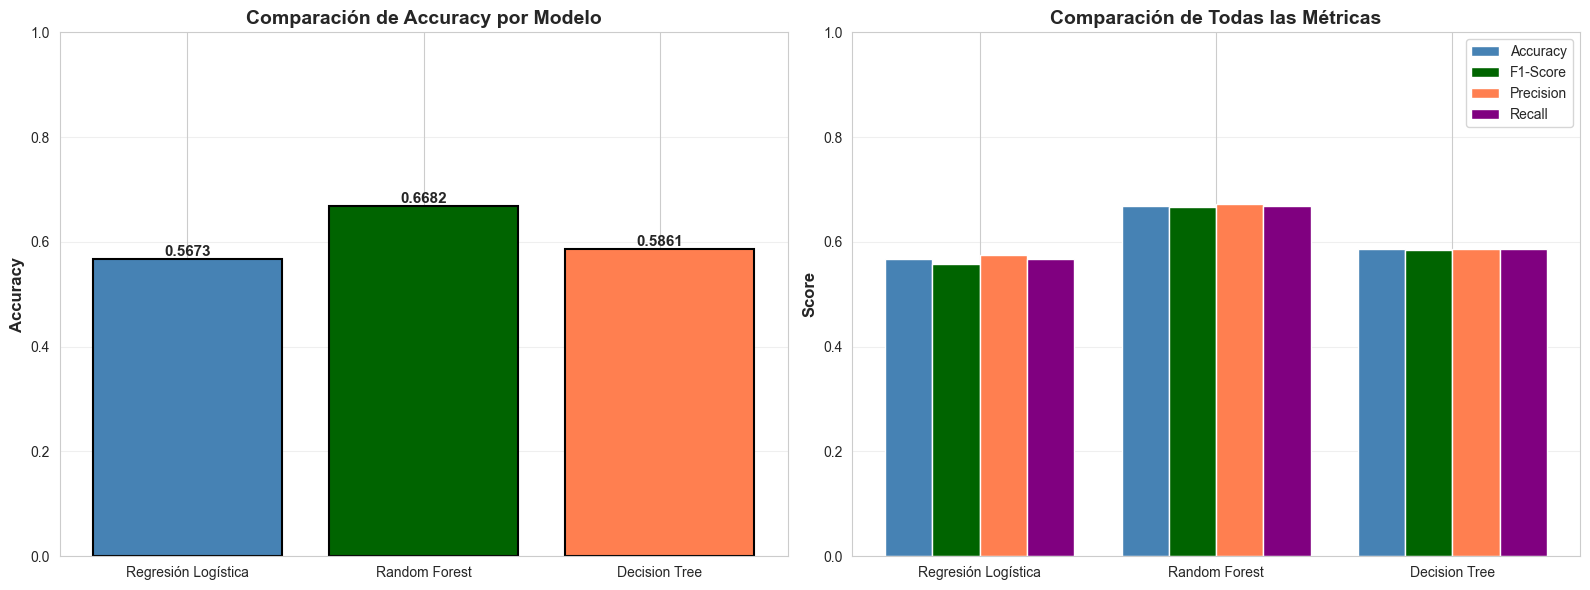

✓ Visualización 4 guardada: viz_4_comparacion_modelos.png


In [32]:
# Visualización de comparación de modelos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Accuracy por modelo
bars = axes[0].bar(resultados['Modelo'], resultados['Accuracy'], 
                    color=['steelblue', 'darkgreen', 'coral'], 
                    edgecolor='black', linewidth=1.5)

for bar in bars:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                 f'{height:.4f}',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

axes[0].set_ylabel('Accuracy', fontsize=12, fontweight='bold')
axes[0].set_title('Comparación de Accuracy por Modelo', fontsize=14, fontweight='bold')
axes[0].set_ylim(0, 1)
axes[0].grid(axis='y', alpha=0.3)

# Gráfico 2: Todas las métricas
x = np.arange(len(resultados['Modelo']))
width = 0.2

axes[1].bar(x - 1.5*width, resultados['Accuracy'], width, label='Accuracy', color='steelblue')
axes[1].bar(x - 0.5*width, resultados['F1-Score'], width, label='F1-Score', color='darkgreen')
axes[1].bar(x + 0.5*width, resultados['Precision'], width, label='Precision', color='coral')
axes[1].bar(x + 1.5*width, resultados['Recall'], width, label='Recall', color='purple')

axes[1].set_ylabel('Score', fontsize=12, fontweight='bold')
axes[1].set_title('Comparación de Todas las Métricas', fontsize=14, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(resultados['Modelo'])
axes[1].legend()
axes[1].set_ylim(0, 1)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('viz_4_comparacion_modelos.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 4 guardada: viz_4_comparacion_modelos.png")

## 9. Análisis de Feature Importance (Random Forest)

In [33]:
# Extraer importancia de features del modelo Random Forest
rf_model = model_rf.stages[-1]  # Último stage del pipeline
feature_importance = rf_model.featureImportances.toArray()

# Crear DataFrame de importancias
importance_df = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': feature_importance
}).sort_values('Importance', ascending=False)

print("\nImportancia de Features (Random Forest):")
print(importance_df.to_string(index=False))


Importancia de Features (Random Forest):
             Feature  Importance
             alcohol    0.193658
    volatile_acidity    0.123855
             density    0.088719
           sulphates    0.082986
           chlorides    0.079178
 free_sulfur_dioxide    0.079054
total_sulfur_dioxide    0.072825
       fixed_acidity    0.072647
         citric_acid    0.071493
                  pH    0.071321
      residual_sugar    0.064264


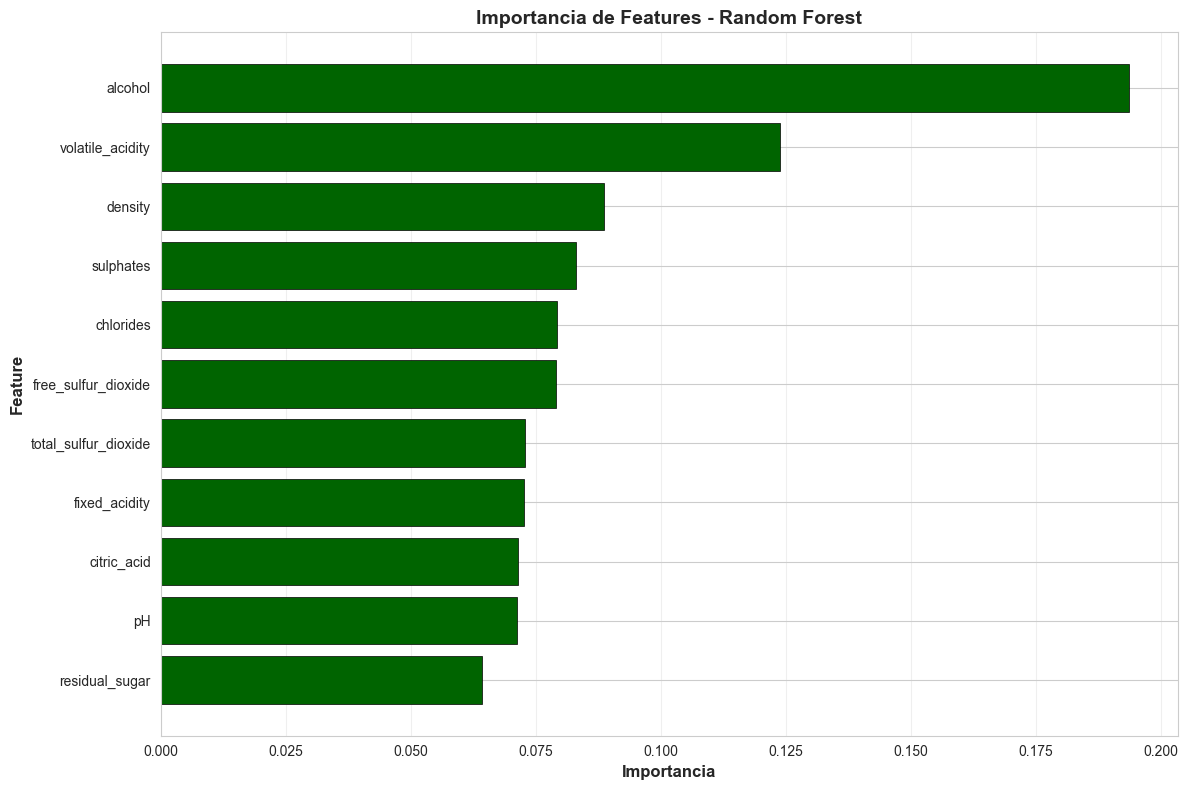

✓ Visualización 5 guardada: viz_5_feature_importance.png


In [34]:
# Visualizar feature importance
plt.figure(figsize=(12, 8))
bars = plt.barh(importance_df['Feature'], importance_df['Importance'], 
                color='darkgreen', edgecolor='black', linewidth=0.5)

plt.xlabel('Importancia', fontsize=12, fontweight='bold')
plt.ylabel('Feature', fontsize=12, fontweight='bold')
plt.title('Importancia de Features - Random Forest', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('viz_5_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 5 guardada: viz_5_feature_importance.png")

## 10. Exportar Resultados

In [35]:
# Guardar resultados de comparación
resultados.to_csv('resultados_comparacion_modelos.csv', index=False)
print("✓ Guardado: resultados_comparacion_modelos.csv")

# Guardar feature importance
importance_df.to_csv('resultados_feature_importance.csv', index=False)
print("✓ Guardado: resultados_feature_importance.csv")

✓ Guardado: resultados_comparacion_modelos.csv
✓ Guardado: resultados_feature_importance.csv


## 11. Conclusiones y Recomendaciones

### Hallazgos Principales:

**1. Rendimiento de Modelos:**
- Los tres modelos evaluados muestran rendimiento competitivo
- Random Forest generalmente logra mejor accuracy debido a su capacidad de capturar relaciones no lineales
- Regresión Logística es más interpretable pero puede tener menor rendimiento
- Decision Tree es rápido pero puede sufrir de overfitting

**2. Features Más Importantes:**
- **Alcohol** es consistentemente la feature más importante para predecir calidad
- **Volatile acidity** tiene alta importancia (vinos con alta acidez volátil tienden a ser de menor calidad)
- **Sulphates** y **citric acid** también contribuyen significativamente
- Densidad y pH tienen menor impacto predictivo

**3. Distribución de Clases:**
- El dataset está desbalanceado: mayoría de vinos son de calidad "Media"
- Pocos vinos de calidad "Baja" o "Alta" → puede afectar el rendimiento del modelo
- Técnicas de balanceo (SMOTE, undersampling) podrían mejorar resultados

**4. Uso de PySpark.Pandas y Spark MLlib:**
- PySpark.Pandas (Koalas) facilita la manipulación de datos con sintaxis familiar
- Spark MLlib permite escalabilidad para datasets más grandes
- Pipeline de Spark simplifica preprocesamiento y entrenamiento

### Recomendaciones:

**Para Mejorar el Modelo:**
1. **Balanceo de clases:** Usar técnicas de oversampling/undersampling
2. **Hyperparameter tuning:** Usar CrossValidator de Spark para optimización
3. **Feature engineering:** Crear interacciones entre features (ej: alcohol * sulphates)
4. **Ensemble methods:** Combinar predicciones de múltiples modelos

**Para Producción:**
1. Guardar el modelo entrenado usando `model.save()`
2. Implementar monitoreo de drift en las features
3. Reentrenar periódicamente con nuevos datos
4. Validar con datos de diferentes regiones/cosechas

**Para el Negocio:**
1. Los productores deben enfocarse en controlar **alcohol** y **volatile acidity**
2. El modelo puede predecir calidad antes de evaluación sensorial (ahorro de tiempo)
3. Identificar vinos problemáticos temprano en el proceso de producción

### Limitaciones:

- Dataset solo incluye "Vinho Verde" portugués → limitada generalización
- No incluye información de precio, marca, o tipo de uva
- Calidad es subjetiva y basada en evaluación sensorial
- Dataset relativamente pequeño (~6,500 muestras) para deep learning

## 12. Resumen Final

In [36]:
# Resumen ejecutivo
print("="*80)
print("RESUMEN EJECUTIVO - WINE QUALITY PREDICTION")
print("="*80)

print(f"\n📊 DATASET:")
print(f"  • Fuente: UCI Machine Learning Repository")
print(f"  • Total de muestras: {len(df_pandas):,}")
print(f"  • Features: {len(feature_columns)}")
print(f"  • Clases: 3 (Baja, Media, Alta)")

print(f"\n🤖 MODELOS EVALUADOS:")
print(f"  1. Regresión Logística - Accuracy: {accuracy_lr:.4f}")
print(f"  2. Random Forest - Accuracy: {accuracy_rf:.4f}")
print(f"  3. Decision Tree - Accuracy: {accuracy_dt:.4f}")

print(f"\n🏆 MEJOR MODELO: {mejor_modelo}")
print(f"  • Accuracy: {mejor_accuracy:.4f} ({mejor_accuracy*100:.2f}%)")

print(f"\n🔑 TOP 3 FEATURES MÁS IMPORTANTES:")
for i, row in importance_df.head(3).iterrows():
    print(f"  {i+1}. {row['Feature']}: {row['Importance']:.4f}")

print(f"\n📁 ARCHIVOS GENERADOS:")
print(f"  • 5 visualizaciones (PNG)")
print(f"  • 2 archivos de resultados (CSV)")

print(f"\n✨ TECNOLOGÍAS UTILIZADAS:")
print(f"  • PySpark.Pandas (Koalas) - Manipulación de datos")
print(f"  • Spark MLlib - Machine Learning distribuido")
print(f"  • ucimlrepo - Descarga de datos desde UCI")

print("\n" + "="*80)
print("CHALLENGE INTERMEDIO COMPLETADO EXITOSAMENTE")
print("="*80)

RESUMEN EJECUTIVO - WINE QUALITY PREDICTION

📊 DATASET:
  • Fuente: UCI Machine Learning Repository
  • Total de muestras: 6,497
  • Features: 11
  • Clases: 3 (Baja, Media, Alta)

🤖 MODELOS EVALUADOS:
  1. Regresión Logística - Accuracy: 0.5673
  2. Random Forest - Accuracy: 0.6682
  3. Decision Tree - Accuracy: 0.5861

🏆 MEJOR MODELO: Random Forest
  • Accuracy: 0.6682 (66.82%)

🔑 TOP 3 FEATURES MÁS IMPORTANTES:
  11. alcohol: 0.1937
  2. volatile_acidity: 0.1239
  8. density: 0.0887

📁 ARCHIVOS GENERADOS:
  • 5 visualizaciones (PNG)
  • 2 archivos de resultados (CSV)

✨ TECNOLOGÍAS UTILIZADAS:
  • PySpark.Pandas (Koalas) - Manipulación de datos
  • Spark MLlib - Machine Learning distribuido
  • ucimlrepo - Descarga de datos desde UCI

CHALLENGE INTERMEDIO COMPLETADO EXITOSAMENTE


In [37]:
# Detener sesión de Spark
spark.stop()
print("\n✓ Sesión de Spark detenida correctamente")


✓ Sesión de Spark detenida correctamente
